# NB 07 — SrTiO$_3$ benchmarks (Ω triangulation, YS-vs-Vogt damping, LST, η policy)

Turn 4B Amendment-2 §6. Benchmark notebook: consumes only `literature_io`.
(1) Multi-source $\Omega_{\rm TO1}(T)$ triangulation + cross-method flag;
(2) YS 1969 vs Vogt 1995 $\Gamma(T)$ on a common HWHM basis (~2.4× raw / ~1.2× residual);
(3) LST consistency (Verdi $1/\epsilon$ vs $\Omega^2$, R²≈0.998);
(4) η source policy (Vogt primary γ/2, YS cross-check; cubic η uses `cubic_F1u` ≥110 K only).
**GATE:** stop for sign-off if experimental-anchor cross-method spread > 30%.


In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    return start

PROJECT_ROOT = _find_project_root(Path.cwd())
SRC = PROJECT_ROOT / "src"
if SRC.exists() and str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
FIG_DIR = PROJECT_ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)
CM1 = 0.1239841984

from fekappa.plots import set_publication_style
from fekappa import literature_io as lit
set_publication_style()

FLAGS = []
def flag(item, ok, note=""):
    print(f"  [{'OK ' if ok else 'STOP'}] {item}" + (f"  ({note})" if note else "")); FLAGS.append((item, ok, note))

def nearest(df, T, col, **filt):
    d = df.copy()
    for k, v in filt.items(): d = d[d[k] == v]
    d = d.dropna(subset=[col])
    i = (d["T_K"].astype(float) - T).abs().idxmin()
    return float(d.loc[i, col]), float(d.loc[i, "T_K"])
print("PROJECT_ROOT:", PROJECT_ROOT)


PROJECT_ROOT: /Users/syed.a.moid/Documents/WORKSPACES/PHD/TC/ferroelectric-kappa-scph


## 1. Multi-source $\Omega_{\rm TO1}(T)$ triangulation + cross-method flag


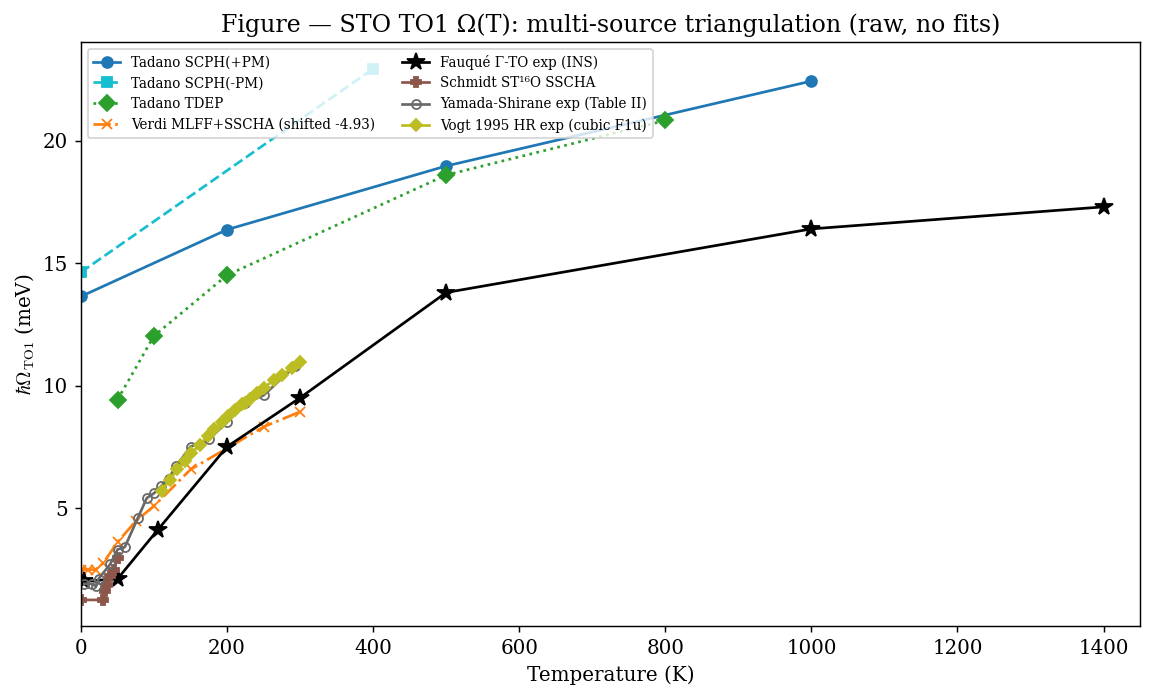

sources: 6 papers (7 curves incl. Tadano +PM/-PM/TDEP); +Vogt F1u dense (Wave Vogt)
saved fig_STO_omega_T_triangulation.{png,pdf}


In [2]:
ta = lit.load_tadano2015_scph_omega_T(); ta1 = ta[ta["mode"] == "TO1"]
vd = lit.load_verdi_sscha_omega_T()
fq = lit.load_fauque2022_omega_T(); fq_to = fq[(fq["mode"] == "TO") & (fq["method"] == "experimental")].sort_values("T_K")
sc = lit.load_schmidt2025_omega_T(); sc16 = sc[(sc["isotope"] == "ST16O") & (sc["method"] == "SSCHA")].sort_values("T_K")
ys = lit.load_yamada_shirane_omega_T(); ys0 = ys[ys["condition_direction"] == "q_0_TO_soft"].sort_values("T_K")
vg = lit.load_vogt1995_sto_omega_T(); vgf = vg[vg["phase_mode"] == "cubic_F1u"].sort_values("T_K")

fig, ax = plt.subplots(figsize=(9, 5.5))
sty = {"SCPH_with_PM": ("o","tab:blue","-","Tadano SCPH(+PM)"),
       "SCPH_without_PM": ("s","tab:cyan","--","Tadano SCPH(-PM)"),
       "TDEP": ("D","tab:green",":","Tadano TDEP")}
for m,(mk,co,ls,lab) in sty.items():
    sub = ta1[ta1["method"] == m].sort_values("T_K")
    ax.plot(sub["T_K"], sub["Omega_meV"], marker=mk, color=co, ls=ls, ms=6, label=lab)
vm = vd[vd["method"] == "MLFF_SSCHA"].sort_values("T_K")
ax.plot(vm["T_K"], vm["Omega_meV"], marker="x", color="tab:orange", ls="-.", label="Verdi MLFF+SSCHA (shifted -4.93)")
ax.plot(fq_to["T_K"], fq_to["omega_meV"], marker="*", color="black", ls="-", ms=10, label="Fauqué Γ-TO exp (INS)")
ax.plot(sc16["T_K"], sc16["Omega_meV"], marker="P", color="tab:brown", ls="-", ms=6, label="Schmidt ST¹⁶O SSCHA")
ax.plot(ys0["T_K"], ys0["omega_meV"], marker="o", color="dimgray", ls="-", ms=5, mfc="none", label="Yamada-Shirane exp (Table II)")
ax.plot(vgf["T_K"], vgf["Omega_meV"], marker="D", color="tab:olive", ls="-", ms=5, label="Vogt 1995 HR exp (cubic F1u)")
ax.set_xlim(0, 1450); ax.set_xlabel("Temperature (K)"); ax.set_ylabel(r"$\hbar\Omega_{\rm TO1}$ (meV)")
ax.set_title("Figure — STO TO1 Ω(T): multi-source triangulation (raw, no fits)")
ax.legend(fontsize=7.5, loc="upper left", ncol=2)
fig.tight_layout()
for ext in ("png","pdf"): fig.savefig(FIG_DIR / f"fig_STO_omega_T_triangulation.{ext}", dpi=150, bbox_inches="tight")
plt.show()
n_papers = 6  # Tadano, Verdi, Fauqué, Schmidt, YS, Vogt (Tadano embeds Servoin+YS exp overlays)
print(f"sources: {n_papers} papers (7 curves incl. Tadano +PM/-PM/TDEP); +Vogt F1u dense (Wave Vogt)")
print("saved fig_STO_omega_T_triangulation.{png,pdf}")


### 1b. Cross-method flag (experimental q=0 anchors)


In [3]:
# Kernel-relevant comparison: the three EXPERIMENTAL q=0 anchors at ~300 K.
# (Computed curves carry method/shift offsets -- documented content, not the flag.)
T_ref = 300.0
fq300,_  = nearest(fq_to, T_ref, "omega_meV")
ys300,tY = nearest(ys0,  T_ref, "omega_meV")
vg300,_  = nearest(vgf,  T_ref, "Omega_meV")
anchors = {"Fauqué": fq300, "YS(Table II)": ys300, "Vogt F1u": vg300}
spread = (max(anchors.values()) - min(anchors.values())) / min(anchors.values())
print(f"Experimental q=0 anchors @~{T_ref:.0f} K (meV): " + ", ".join(f"{k}={v:.2f}" for k,v in anchors.items()))
print(f"  (YS nearest T = {tY:.0f} K)")
print(f"  cross-method spread = {100*spread:.1f}% (max/min)")
flag("STO experimental Ω(T) cross-method spread <= 30%", spread <= 0.30, f"{100*spread:.1f}% @300K (Fauqué/YS/Vogt)")
print()
print("Note: computed curves (Tadano SCPH+PM high, Verdi shifted -4.93, Schmidt ST16O")
print("low-T only) span more by construction (method + shift conventions, annotated in")
print("the figure) -- that spread is documented content, not a data-error flag.")


Experimental q=0 anchors @~300 K (meV): Fauqué=9.50, YS(Table II)=10.80, Vogt F1u=10.96
  (YS nearest T = 293 K)
  cross-method spread = 15.4% (max/min)
  [OK ] STO experimental Ω(T) cross-method spread <= 30%  (15.4% @300K (Fauqué/YS/Vogt))

Note: computed curves (Tadano SCPH+PM high, Verdi shifted -4.93, Schmidt ST16O
low-T only) span more by construction (method + shift conventions, annotated in
the figure) -- that spread is documented content, not a data-error flag.


## 2. YS 1969 vs Vogt 1995 Γ(T) — common HWHM basis (§3.3)


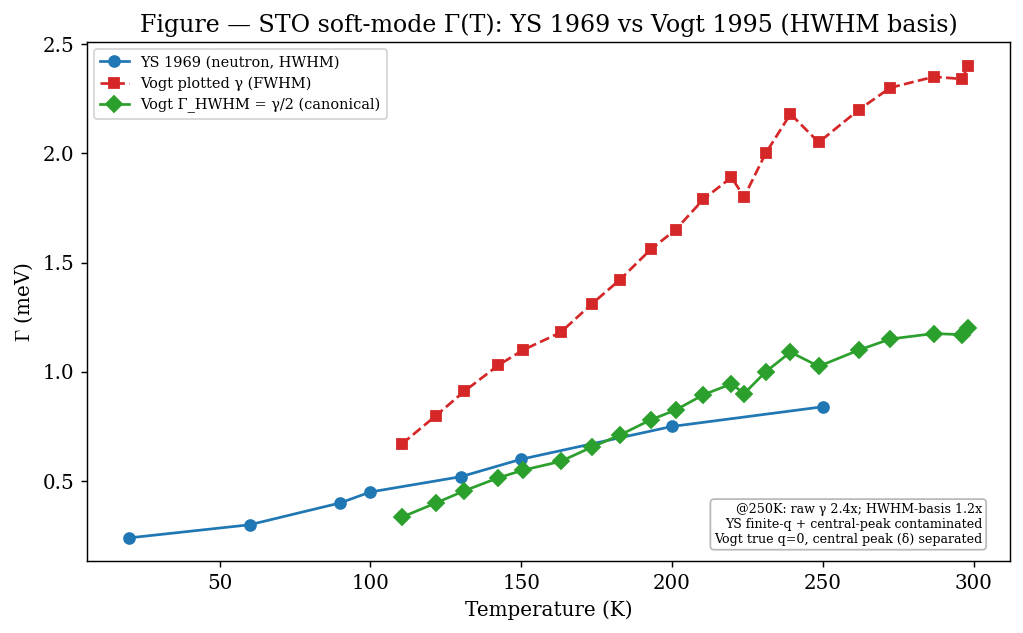

YS-vs-Vogt @250K: raw 2.44x, HWHM-basis residual 1.22x (documented physics, not error)
  [OK ] YS-vs-Vogt spread documented (NOT reconciled to equality)  (raw 2.44x, residual 1.22x)


In [4]:
# YS gamma = HWHM (use directly); Vogt plotted gamma = FWHM -> HWHM = gamma/2.
ysg = lit.load_yamada_shirane_gamma_T().sort_values("T_K")
vgg = lit.load_vogt1995_sto_gamma_T(); vggc = vgg[vgg["phase_mode"] == "cubic_F1u"].sort_values("T_K")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ysg["T_K"], ysg["gamma_meV"], marker="o", color="tab:blue", ls="-", label="YS 1969 (neutron, HWHM)")
ax.plot(vggc["T_K"], vggc["gamma_meV"], marker="s", color="tab:red", ls="--", label="Vogt plotted γ (FWHM)")
ax.plot(vggc["T_K"], vggc["gamma_meV"] / 2, marker="D", color="tab:green", ls="-", label="Vogt Γ_HWHM = γ/2 (canonical)")
ax.set_xlabel("Temperature (K)"); ax.set_ylabel(r"$\Gamma$ (meV)")
ax.set_title("Figure — STO soft-mode Γ(T): YS 1969 vs Vogt 1995 (HWHM basis)")
ax.legend(fontsize=8, loc="upper left")
# quantify spread at 250 K (common HWHM basis)
ys250,_ = nearest(ysg, 250, "gamma_meV")
vg250,_ = nearest(vggc, 250, "gamma_meV")
raw = vg250 / ys250; resid = (vg250/2) / ys250
ax.text(0.97, 0.03, f"@250K: raw γ {raw:.1f}x; HWHM-basis {resid:.1f}x\n"
        "YS finite-q + central-peak contaminated\nVogt true q=0, central peak (δ) separated",
        transform=ax.transAxes, fontsize=7, ha="right", va="bottom",
        bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9))
fig.tight_layout()
for ext in ("png","pdf"): fig.savefig(FIG_DIR / f"fig_YS_vs_Vogt_STO_damping.{ext}", dpi=150, bbox_inches="tight")
plt.show()
print(f"YS-vs-Vogt @250K: raw {raw:.2f}x, HWHM-basis residual {resid:.2f}x (documented physics, not error)")
flag("YS-vs-Vogt spread documented (NOT reconciled to equality)", raw > 2.0, f"raw {raw:.2f}x, residual {resid:.2f}x")


## 3. LST consistency — Verdi $1/\epsilon$ vs $\Omega^2$


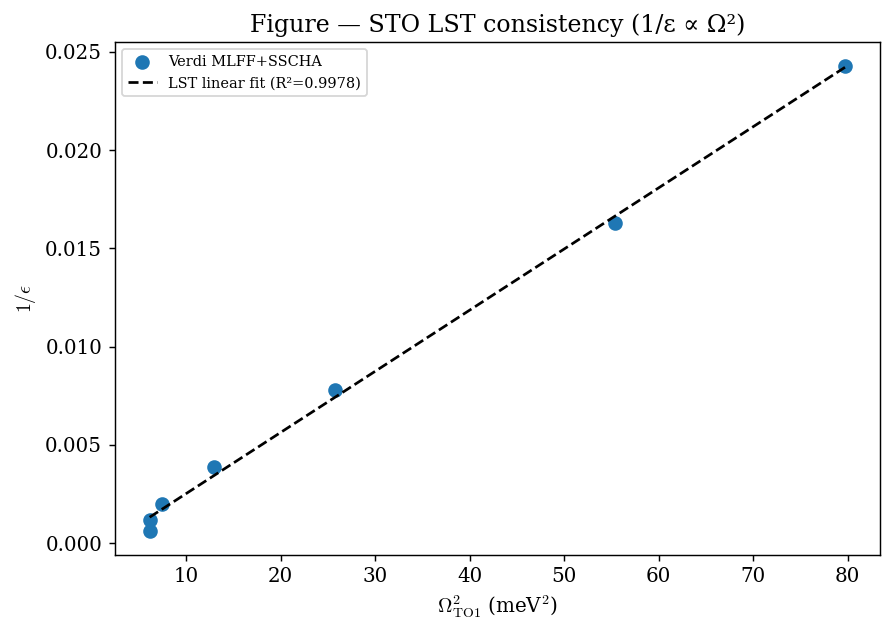

LST 1/eps vs Omega^2 linear fit: R^2 = 0.9978 (7 matched T)
  [OK ] STO LST R^2 >= 0.9  (R^2=0.9978)


In [5]:
eps = lit.load_verdi_inverse_dielectric_T(); em = eps[eps["method"] == "MLFF_SSCHA"].sort_values("T_K")
om = vd[vd["method"] == "MLFF_SSCHA"].sort_values("T_K")
merged = em.merge(om[["T_K","Omega_meV"]], on="T_K", how="inner")
x = (merged["Omega_meV"].astype(float))**2; y = merged["inverse_epsilon"].astype(float)
A = np.vstack([x, np.ones_like(x)]).T
(slope, intc), *_ = np.linalg.lstsq(A, y, rcond=None)
yhat = slope*x + intc
ss_res = ((y-yhat)**2).sum(); ss_tot = ((y-y.mean())**2).sum(); R2 = 1 - ss_res/ss_tot
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, s=50, color="tab:blue", label="Verdi MLFF+SSCHA")
xr = np.linspace(x.min(), x.max(), 50); ax.plot(xr, slope*xr+intc, "k--", label=f"LST linear fit (R²={R2:.4f})")
ax.set_xlabel(r"$\Omega_{\rm TO1}^2$ (meV$^2$)"); ax.set_ylabel(r"$1/\epsilon$")
ax.set_title("Figure — STO LST consistency (1/ε ∝ Ω²)"); ax.legend(fontsize=8)
fig.tight_layout()
for ext in ("png","pdf"): fig.savefig(FIG_DIR / f"fig_STO_LST_consistency.{ext}", dpi=150, bbox_inches="tight")
plt.show()
print(f"LST 1/eps vs Omega^2 linear fit: R^2 = {R2:.4f} ({len(merged)} matched T)")
flag("STO LST R^2 >= 0.9", R2 >= 0.9, f"R^2={R2:.4f}")


## 4. η source policy


In [6]:
print("STO eta source policy (Amendment-2 §4):")
print(" - PRIMARY: Vogt 1995 Fig. 6 cubic_F1u Omega(T) and gamma(T) -> eta_fit,")
print("   gamma -> gamma/2 (FWHM->HWHM) at the eta.py consumption layer. True q=0,")
print("   central peak (delta) separated -> kernel-relevant intrinsic damping.")
print(" - cubic eta_STO uses cubic_F1u (>=110 K) ONLY; transition_merged (85-98 K)")
print("   and sub-105 K A2u/Eu split points are discussion-only (low-T QPE behaviour).")
print(" - CROSS-CHECK: YS 1969 gamma (HWHM, finite-q-analyzed, central-peak-contaminated)")
print("   + Tadano 2015 single-T anchor + STO IR Lorentz proxy. The ~2.4x raw / ~1.2x")
print("   HWHM-basis YS-vs-Vogt spread is documented content (q-resolution + central peak).")
# eta_STO endpoint (cubic_F1u, HWHM basis) for the record
sO = float(vgf["Omega_meV"].iloc[-1]); sG = float(vggc["gamma_meV"].iloc[-1])
print(f"\n eta_STO(~300K) = (gamma/2)/Omega = ({sG:.2f}/2)/{sO:.2f} = {0.5*sG/sO:.3f} (HWHM basis)")
print(" (locked 0.109 +/- ~0.02 reading uncertainty; clusters with eta_KTO~0.127, both <0.5)")


STO eta source policy (Amendment-2 §4):
 - PRIMARY: Vogt 1995 Fig. 6 cubic_F1u Omega(T) and gamma(T) -> eta_fit,
   gamma -> gamma/2 (FWHM->HWHM) at the eta.py consumption layer. True q=0,
   central peak (delta) separated -> kernel-relevant intrinsic damping.
 - cubic eta_STO uses cubic_F1u (>=110 K) ONLY; transition_merged (85-98 K)
   and sub-105 K A2u/Eu split points are discussion-only (low-T QPE behaviour).
 - CROSS-CHECK: YS 1969 gamma (HWHM, finite-q-analyzed, central-peak-contaminated)
   + Tadano 2015 single-T anchor + STO IR Lorentz proxy. The ~2.4x raw / ~1.2x
   HWHM-basis YS-vs-Vogt spread is documented content (q-resolution + central peak).

 eta_STO(~300K) = (gamma/2)/Omega = (2.40/2)/10.96 = 0.109 (HWHM basis)
 (locked 0.109 +/- ~0.02 reading uncertainty; clusters with eta_KTO~0.127, both <0.5)


## 5. Gate


In [7]:
n_stop = sum(1 for _, ok, _ in FLAGS if not ok)
print("\nNB 07 flags:")
for item, ok, note in FLAGS:
    print(f"  [{'OK ' if ok else 'STOP'}] {item}" + (f"  ({note})" if note else ""))
print()
if n_stop:
    print(f"NB 07 GATE: STOP FOR SIGN-OFF ({n_stop} flag(s) tripped).")
else:
    print("NB 07 GATE: PASS. STO triangulation + YS-vs-Vogt + LST consistent; STOP for sign-off (planned).")



NB 07 flags:
  [OK ] STO experimental Ω(T) cross-method spread <= 30%  (15.4% @300K (Fauqué/YS/Vogt))
  [OK ] YS-vs-Vogt spread documented (NOT reconciled to equality)  (raw 2.44x, residual 1.22x)
  [OK ] STO LST R^2 >= 0.9  (R^2=0.9978)

NB 07 GATE: PASS. STO triangulation + YS-vs-Vogt + LST consistent; STOP for sign-off (planned).
